In [1]:
# Import modules
import numpy as np
import math
import random
import matplotlib.pyplot as plt

In [2]:
# Set joint angles limits 
lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

# Set arm link lenghts
d2 = d4 = d4 = d6 = 0.03
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

In [3]:
# Calculate the transforms to calculate the 
# position of a link with respect to its parent link
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

# Calculate the final position after 7 transforms
def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix by dot multiplication
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Get the position of 'n'th link instead of end effector
def get_nth_position(params, n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)#
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Plot the resulting joint configuration and end effector pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    print("Position of each link")
    
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

### Differential Evolution Algorithm

In [4]:
# Define the objective function that calculates the distance 
# between current position and target position according to the
# joint angles
def objective_function(joint_angles, target_position):
    # Compute the current position of the end-effector based on joint angles
    current_position = get_end_tip_position(joint_angles)  # Placeholder value
    # Calculate the Euclidean distance to the target position
    distance = np.linalg.norm(current_position - target_position)
    return distance

# Define the differential evolution algorithm
def differential_evolution(objective, target_position, bounds, constraints, pop_size, max_gen, mutation_factor=0.8, crossover_prob=0.7):
    # Initialize population within bounds
    pop = np.random.rand(pop_size, len(bounds)) * (bounds[:, 1] - bounds[:, 0]) + bounds[:, 0]
    pop = np.clip(pop, constraints[0], constraints[1])  # Ensure initial population respects joint limits
    
    best_score = objective(pop[0], target_position)  # Assuming target_position is correctly defined
    best_sol = pop[0]
    score_history = [best_score]  # Initialize history tracking

    for gen in range(max_gen):
        for i in range(pop_size):
            # Mutation
            idxs = [idx for idx in range(pop_size) if idx != i]
            a, b, c = pop[np.random.choice(idxs, 3, replace=False)]
            mutant = np.clip(a + mutation_factor * (b - c), bounds[:, 0], bounds[:, 1])
            mutant = np.clip(mutant, constraints[0], constraints[1])  # Ensure mutant respects joint limits
            
            # Crossover
            cross_points = np.random.rand(len(bounds)) < crossover_prob
            if not np.any(cross_points):
                cross_points[np.random.randint(0, len(bounds))] = True
            trial = np.where(cross_points, mutant, pop[i])
            
            # Selection
            trial_score = objective(trial, target_position)
            if trial_score < best_score:
                best_score, best_sol = trial_score, trial.copy()
                score_history.append(best_score)  # Update history

            if trial_score < objective(pop[i], target_position):
                pop[i] = trial.copy()

        # At first and last 5 iterations, print the gen score
        if max_gen - gen == 5:
            print("\nLast 5 iterations:\n")
        elif max_gen - gen < 5 or gen < 5:
            print(f"Gen: {gen}, Best Score: {best_score}")
     
        # Stop searcing further if score reaches below 0.02
        # as it is an almost exact solution
        if best_score < 0.02:
            print(f"\nGen: {gen}, Best Score: {best_score:.4f}")
            break

    return best_sol, best_score, score_history


## Optimize With Differential Evolution (DE)

Gen: 0, Best Score: 0.3012389938455604
Gen: 1, Best Score: 0.13578911466621488
Gen: 2, Best Score: 0.13101399355820084
Gen: 3, Best Score: 0.10674542818381921
Gen: 4, Best Score: 0.10674542818381921

Gen: 13, Best Score: 0.0121

Best Solution:
[ 1.21099411  1.91354061  0.10170397 -2.02312302  0.16048262  0.5036745
  2.93267371], 
Score: 0.012090389189369279


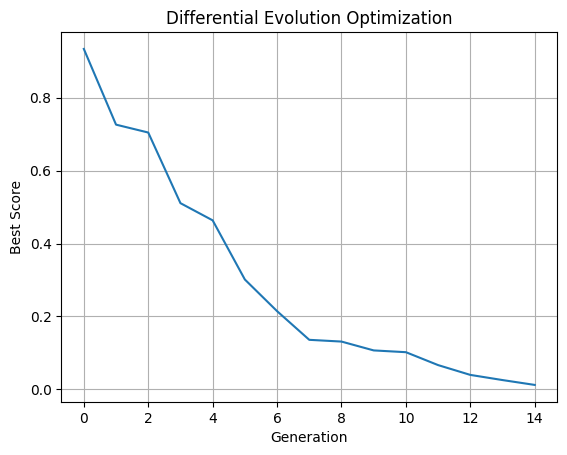

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [-0.02807899  0.01056267  0.34      ]
3: [0.10456508 0.36317342 0.20557079]
4: [0.13213857 0.35170724 0.20270209]
5: [-0.00237422  0.09787332 -0.07564059]
6: [-0.02860932  0.11241233 -0.07622094]


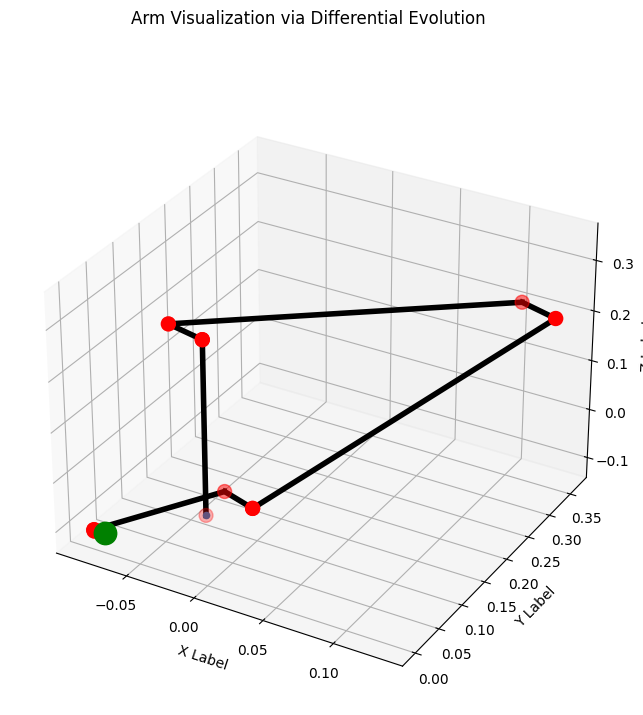

In [5]:
# Algorithm parameters, problem bounds and target position
pop_size = 90
max_gen = 1000
bounds = np.array([(-lim, lim) for lim in [lim1, lim2, lim3, lim4, lim5, lim6, lim7]])

# Choosing a random position to reach for each time code is run
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.2)
target_position = np.array([x,y,z])
#target_position = np.array([-0.3, 0.3, 0.8])

# Solve using Differential Evolution
best_sol, best_score, score_history = differential_evolution(objective_function, target_position, bounds, constraints, pop_size, max_gen)
print(f"\nBest Solution:\n{best_sol}, \nScore: {best_score}")

# Plotting the score history
plt.plot(score_history)
plt.title('Differential Evolution Optimization')
plt.xlabel('Generation')
plt.ylabel('Best Score')
plt.grid(True)
plt.show()

# Plotting the resulting joint configuration and target position.
visualize_config(best_sol, target_position, 'Differential Evolution')
plt.show()